# Identificación de Patrones y Banderas Rojas en Casos de Violencia Intrafamiliar

## Proyecto de Aula: Analítica de Datos para la Transformación Social

**Integrantes:**
- Martin Daniel Montaño B
- Johan Sneider Cortes B

### Problemática

La violencia intrafamiliar constituye una problemática social que requiere herramientas de análisis para comprender las características de los casos registrados y reconocer patrones que puedan orientar acciones de prevención.

Este proyecto analiza registros de violencia intrafamiliar en Colombia durante el periodo 2015-2024, con el propósito de identificar patrones sociodemográficos, temporales, geográficos y relacionados con las circunstancias de los hechos.

El estudio se desarrolla mediante analítica descriptiva. No pretende diagnosticar trastornos de personalidad, atribuir características psicológicas a presuntos agresores ni establecer relaciones causales. Las banderas rojas se entenderán como patrones observables en los registros que merecen atención desde una perspectiva de prevención social.

### Pregunta central

¿Qué patrones sociodemográficos, temporales, geográficos y relacionados con las características de los hechos permiten identificar posibles señales de alerta en los casos de violencia intrafamiliar registrados en Colombia entre 2015 y 2024?

## 1. Preguntas analíticas del proyecto

1. ¿Qué grupos de edad, sexo y ciclo vital presentan la mayor concentración de registros de violencia intrafamiliar?
2. ¿Qué características sociodemográficas presentan mayor frecuencia entre las víctimas registradas?
3. ¿Qué escenarios, circunstancias y características de los hechos aparecen con mayor frecuencia?
4. ¿Cómo se distribuyen los registros por año, mes, departamento y municipio?
5. ¿Qué combinaciones de características aparecen con mayor frecuencia y pueden considerarse patrones de alerta para la prevención social?

Estas preguntas orientan la limpieza, el análisis descriptivo y las visualizaciones que se construirán posteriormente en Power BI.

## 2. Descripción y procedencia del dataset

**Nombre:** Violencia intrafamiliar. Colombia, años 2015 a 2024. Cifras definitivas.

**Entidad:** Instituto Nacional de Medicina Legal y Ciencias Forenses.

**Portal:** Datos Abiertos Colombia.

**Enlace:** https://www.datos.gov.co/Justicia-y-Derecho/Violencia-intrafamiliar-Colombia-a-os-2015-a-2024-/ers2-kerr

**Método de obtención:** consulta de la API pública del conjunto de datos.

**Periodo de estudio:** 2015-2024.

El conjunto contiene variables relacionadas con las características sociodemográficas de las víctimas, la ubicación de los hechos, el contexto de la lesión y otras circunstancias registradas.

La fuente representa los casos registrados en el sistema correspondiente, no necesariamente la totalidad de los hechos ocurridos en el país. Por ello, los resultados se interpretarán como distribuciones de registros y no como una medición completa de la prevalencia de la violencia intrafamiliar.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [ ]:
url_api = (
    "https://www.datos.gov.co/resource/ers2-kerr.csv"
    "?$limit=500000"
)

df_original = pd.read_csv(url_api)

print("Descarga completada.")
print(f"Filas: {len(df_original):,}")
print(f"Columnas: {len(df_original.columns)}")

Descarga completada.
Filas: 236,840
Columnas: 36


## 3. Validación inicial de la base de datos

Se verificará la cantidad de registros y variables descargados, la presencia de los años del periodo de estudio, la unicidad de los identificadores, los registros completamente duplicados y los valores faltantes.

Esta validación permite confirmar que la base corresponde al recurso esperado antes de comenzar la depuración y evita trabajar con una extracción incompleta.

In [ ]:
print("Dimensiones:", df_original.shape)
print("IDs únicos:", df_original["id"].nunique())
print("Duplicados exactos:", df_original.duplicated().sum())
print("Valores nulos totales:", df_original.isnull().sum().sum())

print("\nRegistros por año:")
display(
    df_original["a_o_del_hecho"]
    .value_counts()
    .sort_index()
    .rename_axis("Año")
    .reset_index(name="Cantidad de registros")
)

Dimensiones: (236840, 36)
IDs únicos: 236840
Duplicados exactos: 0
Valores nulos totales: 0

Registros por año:


,Año,Cantidad de registros
0,2015,26985
1,2016,26473
2,2017,27538
3,2018,28645
4,2019,28277
5,2020,16624
6,2021,18043
7,2022,20541
8,2023,23529
9,2024,20185


In [ ]:
# Revisar nombres, tipos de datos y estructura
print("Nombres de las columnas:")
print(df_original.columns.tolist())

print("\nInformación general:")
df_original.info()

print("\nPrimeros cinco registros:")
display(df_original.head())

Nombres de las columnas:
['id', 'a_o_del_hecho', 'sexo_de_la_victima', 'grupo_de_edad_quinquenal', 'grupo_mayor_menor_de_edad', 'grupo_de_edad_judicial', 'ciclo_vital', 'pais_de_nacimiento', 'escolaridad', 'estado_civil', 'tipo_de_discapacidad', 'pertenencia_etnica', 'orientacion_sexual', 'identidad_de_genero', 'transgenero', 'pertenencia_grupal', 'mes_del_hecho', 'dia_del_hecho', 'rango_de_hora_del_hecho_x_3_horas', 'codigo_dane_municipio', 'municipio_del_hecho_dane', 'departamento_del_hecho_dane', 'codigo_dane_departamento', 'localidad_del_hecho', 'zona_del_hecho', 'escenario_del_hecho', 'actividad_durante_el_hecho', 'circunstancia_del_hecho_detallada', 'contexto_del_hecho', 'mecanismo_causal_de_la_lesion_no_fatal', 'diagnostico_topografico_de_la_lesion_no_fatal', 'sexo_del_agresor', 'presunto_agresor_detallado', 'factor_desencadenante_de_la_agresion', 'dias_de_incapacidad_medicolegal', 'pueblo_indigena']

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 236840 

,id,a_o_del_hecho,sexo_de_la_victima,grupo_de_edad_quinquenal,grupo_mayor_menor_de_edad,grupo_de_edad_judicial,ciclo_vital,pais_de_nacimiento,escolaridad,estado_civil,tipo_de_discapacidad,pertenencia_etnica,orientacion_sexual,identidad_de_genero,transgenero,pertenencia_grupal,mes_del_hecho,dia_del_hecho,rango_de_hora_del_hecho_x_3_horas,codigo_dane_municipio,municipio_del_hecho_dane,departamento_del_hecho_dane,codigo_dane_departamento,localidad_del_hecho,zona_del_hecho,escenario_del_hecho,actividad_durante_el_hecho,circunstancia_del_hecho_detallada,contexto_del_hecho,mecanismo_causal_de_la_lesion_no_fatal,diagnostico_topografico_de_la_lesion_no_fatal,sexo_del_agresor,presunto_agresor_detallado,factor_desencadenante_de_la_agresion,dias_de_incapacidad_medicolegal,pueblo_indigena
0,1,2015,Hombre,(10 a 14),a) Menor de Edad (<18 Años),(10 a 13),(12 a 17) Adolescencia,Colombia,Básica primaria,Soltero (a),Ninguna,Sin información,No Sabe / No Informa,No Sabe / No Informa,No Sabe / No Informa,Sin información,Diciembre,martes,(18:00 a 20:59),11001,"Bogotá, D.C.","Bogotá, D.C.",11,Rafael Uribe Uribe,Cabecera municipal,"Calle (Autopista,Avenida,Dentro de La Ciudad)",Actividades de desplazamiento de un lugar a otro.,"Violencia contra niños, niñas y adolescentes","3 Lesiones no Fatales contra Niños, Niñas y Adolescentes por Violencia Intrafamiliar",Abrasivo,Trauma de miembros,Hombre,Padre,"Intolerancia, machismo",1 a 30,No había sido implementada
1,2,2015,Hombre,(00 a 04),a) Menor de Edad (<18 Años),(00 a 04),(00 a 05) Primera Infancia,Colombia,No aplica,No aplica,Ninguna,Sin pertenencia étnica,No aplica,No aplica,No aplica,Sin información,Marzo,miércoles,(18:00 a 20:59),25754,Soacha,Cundinamarca,25,Sin información,Cabecera municipal,Vivienda,"Actividades relacionadas con la asistencia a eventos culturales, de entretenimiento y/o deportivos","Violencia contra niños, niñas y adolescentes","3 Lesiones no Fatales contra Niños, Niñas y Adolescentes por Violencia Intrafamiliar",Contundente,Trauma de miembros,Mujer,Madre,"Intolerancia, machismo",1 a 30,No había sido implementada
2,3,2015,Hombre,(00 a 04),a) Menor de Edad (<18 Años),(00 a 04),(00 a 05) Primera Infancia,Colombia,No aplica,No aplica,Ninguna,Sin pertenencia étnica,No aplica,No aplica,No aplica,Sin información,Junio,jueves,Sin información,25754,Soacha,Cundinamarca,25,Sin información,Cabecera municipal,Sin información,Actividades de desplazamiento de un lugar a otro.,"Violencia contra niños, niñas y adolescentes","3 Lesiones no Fatales contra Niños, Niñas y Adolescentes por Violencia Intrafamiliar",Por determinar,Sin información,Mujer,Otros familiares civiles o consanguineos,"Intolerancia, machismo",Sin información,No había sido implementada
3,4,2015,Hombre,(00 a 04),a) Menor de Edad (<18 Años),(00 a 04),(00 a 05) Primera Infancia,Colombia,No aplica,No aplica,Ninguna,Sin pertenencia étnica,No aplica,No aplica,No aplica,Sin información,Enero,sábado,(06:00 a 08:59),54001,Cúcuta,Norte de Santander,54,Sin información,Cabecera municipal,Vivienda,Actividades de desplazamiento de un lugar a otro.,"Violencia contra niños, niñas y adolescentes","3 Lesiones no Fatales contra Niños, Niñas y Adolescentes por Violencia Intrafamiliar",Contundente,Trauma facial,Mujer,Abuelo (a),"Intolerancia, machismo",1 a 30,No había sido implementada
4,5,2015,Hombre,(25 a 29),b) Mayor de Edad (>18 Años),(25 a 28),(18 a 28) Juventud,Colombia,Sin información,Unión libre,Ninguna,Sin información,Heterosexual,No Sabe / No Informa,No Sabe / No Informa,Sin información,Mayo,martes,(09:00 a 11:59),11001,"Bogotá, D.C.","Bogotá, D.C.",11,Usme,Cabecera municipal,"Calle (Autopista,Avenida,Dentro de La Ciudad)",Actividades de desplazamiento de un lugar a otro.,Violencia entre otros familiares,4 Lesiones no Fatales por Violencia entre otros Familiares,Contundente,Trauma facial,Hombre,Hermano (a),"Intolerancia, machismo",1 a 30,No había sido implementada


## 4. Proceso de depuración

Se creará una copia de la base original para preservar la trazabilidad de los datos.

El proceso contempla:
- Eliminar espacios al inicio y al final de los valores de texto.
- Normalizar las mayúsculas y minúsculas de los meses y días.
- Revisar registros duplicados.
- Revisar valores faltantes y tipos de datos.
- Conservar los registros incompletos cuando sus datos sigan siendo útiles para determinados análisis.

No se imputarán datos ni se eliminarán registros automáticamente sin justificar la decisión. Los códigos geográficos y el identificador se tratarán como identificadores, no como magnitudes cuantitativas.

In [ ]:
df_clean = df_original.copy()

# Limpiar espacios en variables de texto
columnas_texto = df_clean.select_dtypes(
    include=["object", "string"]
).columns

for columna in columnas_texto:
    df_clean[columna] = (
        df_clean[columna]
        .astype("string")
        .str.strip()
    )

# Normalizar los nombres de los meses y días
for columna in ["mes_del_hecho", "dia_del_hecho"]:
    df_clean[columna] = (
        df_clean[columna]
        .str.lower()
        .str.capitalize()
    )

# Asegurar que el año sea numérico
df_clean["a_o_del_hecho"] = pd.to_numeric(
    df_clean["a_o_del_hecho"],
    errors="coerce"
).astype("Int64")

print("Copia de trabajo preparada.")
print("Filas:", len(df_clean))
print("Columnas:", len(df_clean.columns))

Copia de trabajo preparada.
Filas: 236840
Columnas: 36


In [ ]:
# Comparar la calidad de la base antes y después de la depuración
resumen_calidad = pd.DataFrame({
    "Indicador": [
        "Número de filas",
        "Número de columnas",
        "Duplicados exactos",
        "Valores nulos totales"
    ],
    "Antes": [
        len(df_original),
        len(df_original.columns),
        int(df_original.duplicated().sum()),
        int(df_original.isnull().sum().sum())
    ],
    "Después": [
        len(df_clean),
        len(df_clean.columns),
        int(df_clean.duplicated().sum()),
        int(df_clean.isnull().sum().sum())
    ]
})

display(resumen_calidad)

,Indicador,Antes,Después
0,Número de filas,236840,236840
1,Número de columnas,36,36
2,Duplicados exactos,0,0
3,Valores nulos totales,0,0


In [ ]:
# Resumen de valores faltantes por variable
resumen_nulos = pd.DataFrame({
    "Variable": df_clean.columns,
    "Valores nulos": df_clean.isnull().sum().values,
    "Porcentaje nulo": (
        df_clean.isnull().mean().values * 100
    ).round(2)
})

display(
    resumen_nulos.sort_values(
        "Porcentaje nulo",
        ascending=False
    )
)

,Variable,Valores nulos,Porcentaje nulo
0,id,0,0.0
1,a_o_del_hecho,0,0.0
2,sexo_de_la_victima,0,0.0
3,grupo_de_edad_quinquenal,0,0.0
4,grupo_mayor_menor_de_edad,0,0.0
5,grupo_de_edad_judicial,0,0.0
6,ciclo_vital,0,0.0
7,pais_de_nacimiento,0,0.0
8,escolaridad,0,0.0
9,estado_civil,0,0.0


In [ ]:
# Diccionario inicial de variables y tipos
diccionario_variables = pd.DataFrame({
    "Variable": df_clean.columns,
    "Tipo de dato": df_clean.dtypes.astype(str).values,
    "Valores únicos": [
        df_clean[columna].nunique(dropna=True)
        for columna in df_clean.columns
    ]
})

display(diccionario_variables)

,Variable,Tipo de dato,Valores únicos
0,id,int64,236840
1,a_o_del_hecho,Int64,10
2,sexo_de_la_victima,string,2
3,grupo_de_edad_quinquenal,string,19
4,grupo_mayor_menor_de_edad,string,5
5,grupo_de_edad_judicial,string,19
6,ciclo_vital,string,7
7,pais_de_nacimiento,string,43
8,escolaridad,string,20
9,estado_civil,string,8


## 5. Análisis de la distribución temporal

Se calculará la cantidad y el porcentaje de registros correspondientes a cada año del periodo 2015-2024.

Esta distribución permite observar cómo se comporta el número de registros a lo largo del tiempo. Las diferencias anuales no se interpretarán automáticamente como aumentos o disminuciones reales de la violencia, ya que también pueden depender de cambios en el registro y la cobertura de la fuente.

In [ ]:
resumen_anual = (
    df_clean["a_o_del_hecho"]
    .value_counts()
    .sort_index()
    .rename_axis("Año")
    .reset_index(name="Cantidad de registros")
)

resumen_anual["Porcentaje"] = (
    resumen_anual["Cantidad de registros"]
    / len(df_clean) * 100
).round(2)

display(resumen_anual)

,Año,Cantidad de registros,Porcentaje
0,2015,26985,11.39
1,2016,26473,11.18
2,2017,27538,11.63
3,2018,28645,12.09
4,2019,28277,11.94
5,2020,16624,7.02
6,2021,18043,7.62
7,2022,20541,8.67
8,2023,23529,9.93
9,2024,20185,8.52


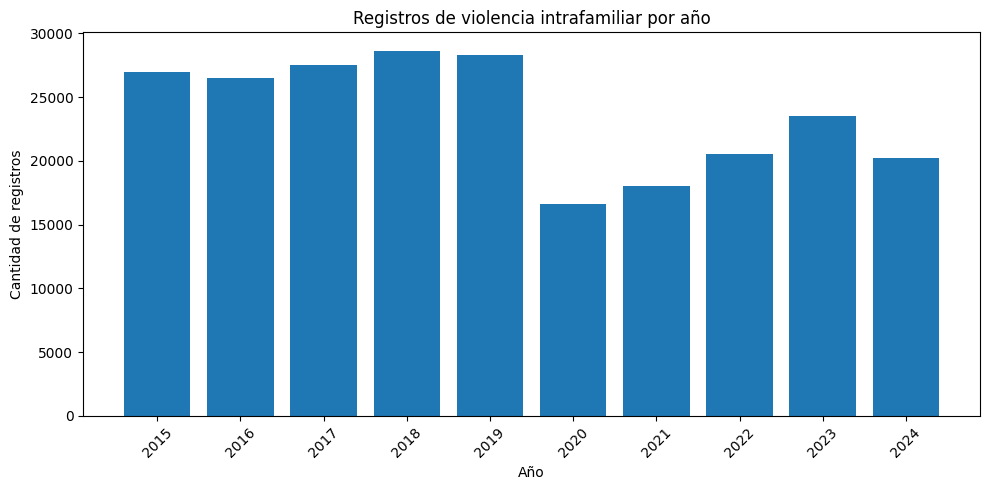

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    resumen_anual["Año"].astype(str),
    resumen_anual["Cantidad de registros"]
)

plt.title("Registros de violencia intrafamiliar por año")
plt.xlabel("Año")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Análisis sociodemográfico

Se analizarán las características sociodemográficas de las víctimas mediante frecuencias absolutas y porcentajes.

Se priorizarán las variables sexo de la víctima, grupo de edad quinquenal, ciclo vital, escolaridad y estado civil. Los resultados permitirán identificar las categorías con mayor presencia dentro de los registros disponibles.

La mayor frecuencia de una categoría no implica por sí misma que esta presente un mayor riesgo individual de sufrir violencia, dado que no se dispone aquí de denominadores poblacionales comparables.

In [ ]:
variables_sociodemograficas = [
    "sexo_de_la_victima",
    "grupo_de_edad_quinquenal",
    "ciclo_vital",
    "escolaridad",
    "estado_civil"
]

def tabla_frecuencias(data, columna):
    frecuencias = (
        data[columna]
        .fillna("Sin dato")
        .value_counts(dropna=False)
        .rename_axis("Categoría")
        .reset_index(name="Frecuencia")
    )

    frecuencias["Porcentaje"] = (
        frecuencias["Frecuencia"] / len(data) * 100
    ).round(2)

    return frecuencias

for columna in variables_sociodemograficas:
    print(f"\nVariable: {columna}")
    display(tabla_frecuencias(df_clean, columna))


Variable: sexo_de_la_victima


,Categoría,Frecuencia,Porcentaje
0,Mujer,140682,59.4
1,Hombre,96158,40.6



Variable: grupo_de_edad_quinquenal


,Categoría,Frecuencia,Porcentaje
0,(10 a 14),29172,12.32
1,(20 a 24),21434,9.05
2,(05 a 09),20827,8.79
3,(15 a 17),19599,8.28
4,(25 a 29),19551,8.25
5,(30 a 34),16899,7.14
6,(35 a 39),14940,6.31
7,(40 a 44),13506,5.7
8,(50 a 54),13136,5.55
9,(00 a 04),13075,5.52



Variable: ciclo_vital


,Categoría,Frecuencia,Porcentaje
0,(29 a 59) Adultez,86606,36.57
1,(18 a 28) Juventud,45939,19.4
2,(12 a 17) Adolescencia,38872,16.41
3,(06 a 11) Infancia,27226,11.5
4,(Más de 60) Adulto Mayor,21617,9.13
5,(00 a 05) Primera Infancia,16575,7.0
6,Sin información,5,0.0



Variable: escolaridad


,Categoría,Frecuencia,Porcentaje
0,Educación básica primaria,61979,26.17
1,Educación básica secundaria o secundaria baja,38331,16.18
2,Educación inicial y educación preescolar,37126,15.68
3,Educación media o secundaria alta,32493,13.72
4,Educación técnica profesional y tecnológica,21259,8.98
5,Sin escolaridad,13811,5.83
6,Básica primaria,12782,5.4
7,Preescolar,7928,3.35
8,Sin información,5670,2.39
9,Básica secundaria,1720,0.73



Variable: estado_civil


,Categoría,Frecuencia,Porcentaje
0,Soltero (a),112118,47.34
1,Unión libre,49762,21.01
2,No aplica,33902,14.31
3,Casado (a),20726,8.75
4,Viudo (a),6935,2.93
5,"Separado (a), Divorciado (a)",6734,2.84
6,"Separado (a), divorciado (a)",3376,1.43
7,Sin información,3287,1.39


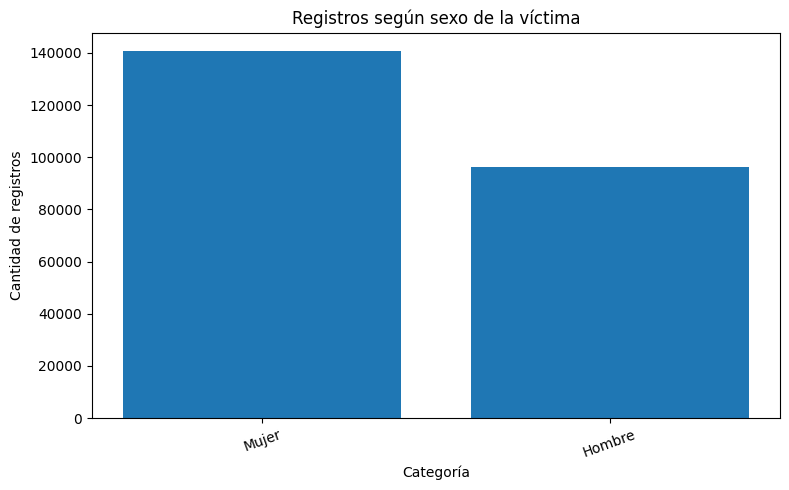

In [ ]:
# Visualización: distribución por sexo de la víctima
frecuencia_sexo = tabla_frecuencias(
    df_clean,
    "sexo_de_la_victima"
)

plt.figure(figsize=(8, 5))
plt.bar(
    frecuencia_sexo["Categoría"],
    frecuencia_sexo["Frecuencia"]
)

plt.title("Registros según sexo de la víctima")
plt.xlabel("Categoría")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 7. Análisis de las características de los hechos

Se estudiarán las variables relacionadas con el contexto de los registros, los escenarios donde ocurrieron los hechos, el presunto agresor, el factor desencadenante y el mecanismo causal de la lesión.

Las frecuencias permitirán identificar las categorías más comunes y orientar la búsqueda de patrones que puedan ser relevantes para la prevención. La información registrada sobre un presunto agresor no se interpretará como una declaración de responsabilidad judicial ni como evidencia de un trastorno psicológico.

In [ ]:
variables_hechos = [
    "escenario_del_hecho",
    "circunstancia_del_hecho_detallada",
    "contexto_del_hecho",
    "presunto_agresor_detallado",
    "factor_desencadenante_de_la_agresion",
    "mecanismo_causal_de_la_lesion_no_fatal"
]

for columna in variables_hechos:
    print(f"\nVariable: {columna}")
    display(tabla_frecuencias(df_clean, columna))


Variable: escenario_del_hecho


,Categoría,Frecuencia,Porcentaje
0,Vivienda,179221,75.67
1,"Calle (Autopista,Avenida,Dentro de La Ciudad)",18378,7.76
2,"Calle (autopista, avenida, dentro de la ciudad)",8231,3.48
3,Vía Pública,7489,3.16
4,Vía pública,4041,1.71
5,"Lugares de Hospedaje (Hoteles,Campamentos Y Otros Tipos de Hospedaje No Permanente,Moteles,Etc)",2221,0.94
6,Sin información,2104,0.89
7,Sin Información,1642,0.69
8,"Establecimiento Comercial (Tienda,Centro Comercial,Almacén,Plaza de Mercado)",1611,0.68
9,Áreas Deportivas y/o Recreativas,1336,0.56



Variable: circunstancia_del_hecho_detallada


,Categoría,Frecuencia,Porcentaje
0,Violencia entre otros familiares,121390,51.25
1,"Violencia contra niños, niñas y adolescentes",76479,32.29
2,Violencia contra el adulto mayor,18786,7.93
3,Intolerancia,14331,6.05
4,Consumo de alcohol y/o sustancias psicoactivas,2576,1.09
5,Embriaguez (alcohólica y no alcohólica),888,0.37
6,Conflicto familiar,828,0.35
7,Celos,379,0.16
8,Sin información,332,0.14
9,Amenaza o intimidación,305,0.13



Variable: contexto_del_hecho


,Categoría,Frecuencia,Porcentaje
0,4 Lesiones no Fatales por Violencia entre otros Familiares,132547,55.96
1,"3 Lesiones no Fatales contra Niños, Niñas y Adolescentes por Violencia Intrafamiliar",82676,34.91
2,5 Lesiones no Fatales contra el Adulto Mayor por Violencia Intrafamiliar,21617,9.13


... (2 outputs left out)


Variable: factor_desencadenante_de_la_agresion


,Categoría,Frecuencia,Porcentaje
0,"Intolerancia, machismo",167780,70.84
1,Consumo de alcohol y/o sustancias psicoactivas,18700,7.9
2,Alcoholismo / drogadicción,18605,7.86
3,Sin información,16881,7.13
4,"Celos, desconfianza, infidelidad",7718,3.26
5,Económicas,2178,0.92
6,Otras razones,2131,0.9
7,Otras,1503,0.63
8,Abandono,725,0.31
9,Enfermedad fisica o mental,506,0.21



Variable: mecanismo_causal_de_la_lesion_no_fatal


,Categoría,Frecuencia,Porcentaje
0,Contundente,108971,46.01
1,Por determinar,47831,20.2
2,Mecanismo múltiple,46502,19.63
3,Corto contundente,15322,6.47
4,Abrasivo,7532,3.18
5,Cortante,4460,1.88
6,Corto punzante,4177,1.76
7,Térmico,739,0.31
8,Biodinámico,401,0.17
9,Proyectil de arma de fuego,368,0.16


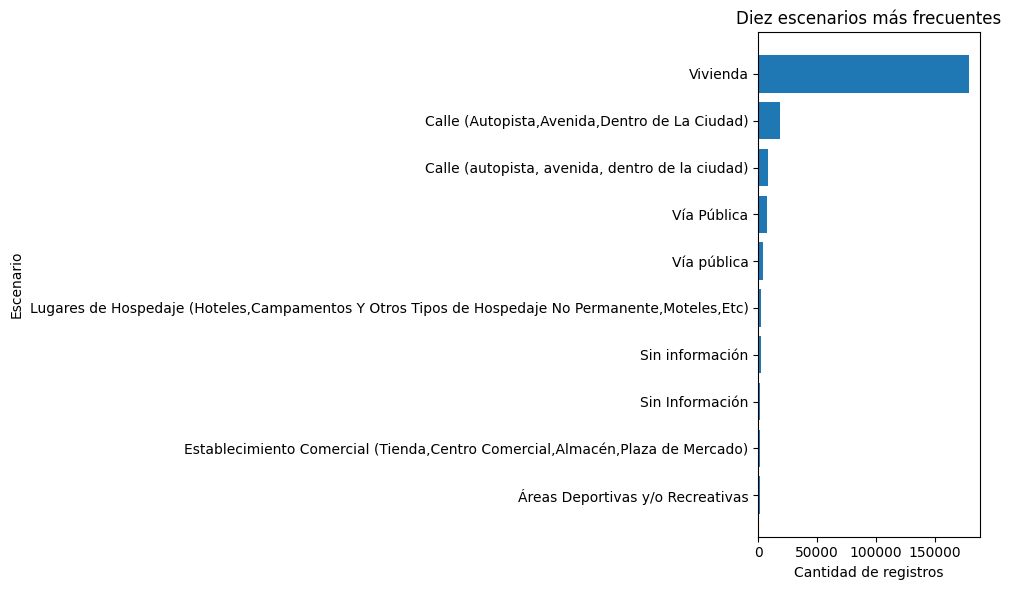

In [ ]:
# Gráfico de los diez escenarios más frecuentes
frecuencia_escenario = tabla_frecuencias(
    df_clean,
    "escenario_del_hecho"
).head(10).sort_values("Frecuencia")

plt.figure(figsize=(10, 6))
plt.barh(
    frecuencia_escenario["Categoría"],
    frecuencia_escenario["Frecuencia"]
)

plt.title("Diez escenarios más frecuentes")
plt.xlabel("Cantidad de registros")
plt.ylabel("Escenario")
plt.tight_layout()
plt.show()

## 8. Análisis geográfico

Se analizará la distribución de los registros por departamento y municipio. Se identificarán las zonas con mayor cantidad de registros y su participación porcentual dentro del conjunto de datos.

Los resultados representan cantidades registradas y no tasas de riesgo. Para comparar el riesgo entre territorios sería necesario incorporar denominadores poblacionales y considerar las diferencias en cobertura y capacidad de registro.

In [ ]:
for columna in [
    "departamento_del_hecho_dane",
    "municipio_del_hecho_dane"
]:
    print(f"\nDiez categorías principales: {columna}")

    display(
        tabla_frecuencias(df_clean, columna).head(10)
    )


Diez categorías principales: departamento_del_hecho_dane


,Categoría,Frecuencia,Porcentaje
0,"Bogotá, D.C.",61428,25.94
1,Antioquia,31087,13.13
2,Cundinamarca,19337,8.16
3,Valle del Cauca,14734,6.22
4,Santander,11705,4.94
5,Atlántico,10687,4.51
6,Tolima,8242,3.48
7,Boyacá,8099,3.42
8,Meta,7525,3.18
9,Norte de Santander,6547,2.76



Diez categorías principales: municipio_del_hecho_dane


,Categoría,Frecuencia,Porcentaje
0,"Bogotá, D.C.",61428,25.94
1,Medellín,16239,6.86
2,Cali,8015,3.38
3,Barranquilla,6700,2.83
4,Villavicencio,5647,2.38
5,Soacha,4867,2.05
6,Ibagué,4230,1.79
7,Cúcuta,4182,1.77
8,Cartagena de Indias,3868,1.63
9,Bucaramanga,3386,1.43


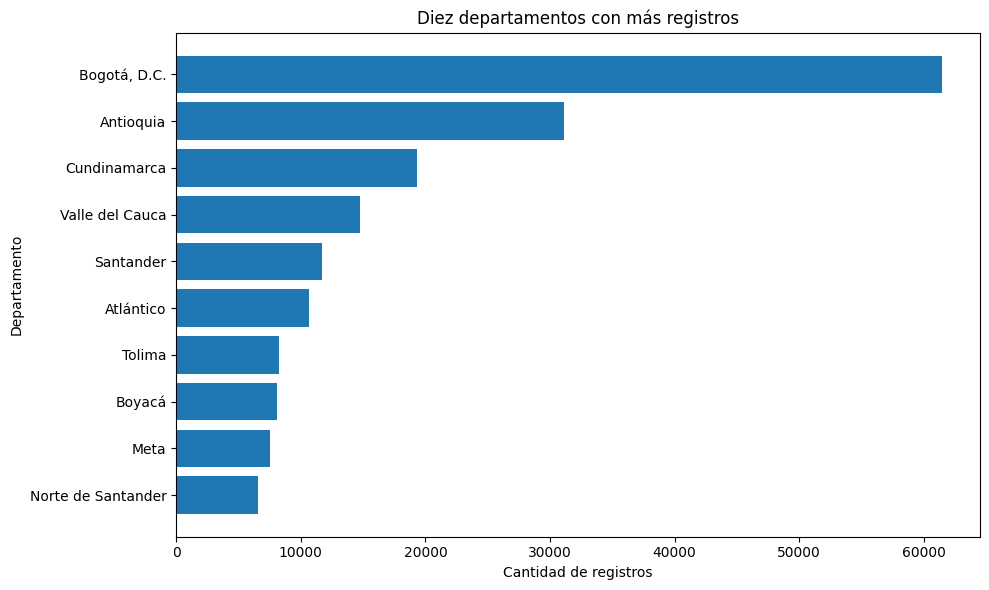

In [ ]:
frecuencia_departamento = (
    df_clean["departamento_del_hecho_dane"]
    .fillna("Sin dato")
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
plt.barh(
    frecuencia_departamento.index,
    frecuencia_departamento.values
)

plt.title("Diez departamentos con más registros")
plt.xlabel("Cantidad de registros")
plt.ylabel("Departamento")
plt.tight_layout()
plt.show()

In [ ]:
print("Registros por mes:")
display(tabla_frecuencias(df_clean, "mes_del_hecho"))

print("\nRegistros por día de la semana:")
display(tabla_frecuencias(df_clean, "dia_del_hecho"))

print("\nRegistros por rango horario:")
display(
    tabla_frecuencias(
        df_clean,
        "rango_de_hora_del_hecho_x_3_horas"
    )
)

Registros por mes:


,Categoría,Frecuencia,Porcentaje
0,Mayo,21435,9.05
1,Septiembre,21070,8.9
2,Agosto,21031,8.88
3,Marzo,20942,8.84
4,Febrero,20386,8.61
5,Julio,20033,8.46
6,Enero,19718,8.33
7,Octubre,19509,8.24
8,Abril,19038,8.04
9,Junio,18962,8.01



Registros por día de la semana:


,Categoría,Frecuencia,Porcentaje
0,Domingo,46617,19.68
1,Lunes,35112,14.83
2,Martes,32748,13.83
3,Miércoles,32337,13.65
4,Sábado,31664,13.37
5,Jueves,30464,12.86
6,Viernes,27898,11.78



Registros por rango horario:


,Categoría,Frecuencia,Porcentaje
0,(18:00 a 20:59),44689,18.87
1,(15:00 a 17:59),33811,14.28
2,(09:00 a 11:59),32298,13.64
3,Sin información,31887,13.46
4,(12:00 a 14:59),31504,13.3
5,(21:00 a 23:59),28361,11.97
6,(06:00 a 08:59),18230,7.7
7,(00:00 a 02:59),8913,3.76
8,(03:00 a 05:59),7147,3.02


## 9. Identificación de patrones y posibles señales de alerta

En esta fase se examinarán combinaciones de variables para identificar patrones frecuentes en los registros. Se analizarán, entre otras, las relaciones descriptivas entre grupo de edad y sexo de la víctima, tipo de presunto agresor y escenario del hecho.

Se considerará posible señal de alerta un patrón observable con una frecuencia o concentración relevante que justifique atención desde la prevención social. Esta clasificación no equivale a una predicción clínica, una prueba de causalidad ni una evaluación individual del riesgo.

Los patrones identificados se interpretarán teniendo en cuenta la cobertura, la calidad y las limitaciones del conjunto de datos.

In [ ]:
# Combinación 1: grupo de edad y sexo de la víctima
patron_edad_sexo = pd.crosstab(
    df_clean["grupo_de_edad_quinquenal"],
    df_clean["sexo_de_la_victima"]
)

display(patron_edad_sexo)

sexo_de_la_victima,Hombre,Mujer
grupo_de_edad_quinquenal,,
(00 a 04),7064,6011
(05 a 09),11337,9490
(10 a 14),13269,15903
(15 a 17),7586,12013
(18 a 19),2641,5880
(20 a 24),7193,14241
(25 a 29),6682,12869
(30 a 34),6013,10886
(35 a 39),5222,9718


In [ ]:
# Combinación 2: presunto agresor y escenario
patron_agresor_escenario = (
    df_clean.groupby(
        [
            "presunto_agresor_detallado",
            "escenario_del_hecho"
        ],
        dropna=False
    )
    .size()
    .reset_index(name="Cantidad")
    .sort_values("Cantidad", ascending=False)
)

display(patron_agresor_escenario.head(20))

,presunto_agresor_detallado,escenario_del_hecho,Cantidad
216,Hermano (a),Vivienda,30865
684,Padre,Vivienda,28732
409,Madre,Vivienda,24117
298,Hijo (a),Vivienda,20777
91,Cuñado (a),Vivienda,11365
622,Padrastro,Vivienda,9824
575,Otros familiares civiles o consanguíneos,Vivienda,7450
990,Tío (a),Vivienda,7158
836,Sobrino (a),Vivienda,6341
740,Primo (a),Vivienda,5182


In [ ]:
# Combinación 3: año y sexo de la víctima
patron_anual_sexo = pd.crosstab(
    df_clean["a_o_del_hecho"],
    df_clean["sexo_de_la_victima"]
)

display(patron_anual_sexo)

sexo_de_la_victima,Hombre,Mujer
a_o_del_hecho,,
2015,10647,16338
2016,10819,15654
2017,11075,16463
2018,11636,17009
2019,11480,16797
2020,6687,9937
2021,7327,10716
2022,8320,12221
2023,9828,13701


## 10. Estadística descriptiva de variables cuantitativas

Se revisarán las variables numéricas para determinar cuáles representan cantidades susceptibles de análisis estadístico. Se calcularán media, mediana, desviación estándar, mínimo y máximo únicamente cuando las medidas tengan sentido para la variable estudiada.

Los identificadores y códigos geográficos se excluirán de estas medidas, ya que son etiquetas y no magnitudes. Los grupos de edad y los días de incapacidad expresados mediante intervalos se tratarán como categorías, salvo que la fuente permita recuperar valores numéricos exactos.

In [ ]:
# Seleccionar variables numéricas que sí representan cantidades
# El año se analiza como variable temporal, no como medida de magnitud.
# ID y códigos DANE se excluyen por ser identificadores.

variables_numericas = [
    columna
    for columna in df_clean.select_dtypes(include="number").columns
    if columna not in [
        "id",
        "a_o_del_hecho",
        "codigo_dane_municipio",
        "codigo_dane_departamento"
    ]
]

if variables_numericas:
    estadisticas = (
        df_clean[variables_numericas]
        .describe()
        .T
        [["mean", "50%", "std", "min", "max"]]
        .rename(columns={
            "mean": "Media",
            "50%": "Mediana",
            "std": "Desviación estándar",
            "min": "Mínimo",
            "max": "Máximo"
        })
    )

    display(estadisticas)
else:
    print(
        "No se identificaron variables cuantitativas "
        "continuas adicionales en la extracción."
    )

No se identificaron variables cuantitativas continuas adicionales en la extracción.


## 11. Conclusiones del análisis

Las conclusiones definitivas se redactarán después de examinar las tablas y visualizaciones generadas en las secciones anteriores.

Se responderán las cinco preguntas analíticas del proyecto, destacando los patrones más relevantes en las características sociodemográficas, las circunstancias de los hechos y su distribución temporal y geográfica.

Cada conclusión deberá estar respaldada por cifras del análisis. También se documentarán las limitaciones de la fuente, la posible subrepresentación de casos no registrados y la diferencia entre identificar patrones descriptivos y demostrar causas o diagnosticar condiciones psicológicas.

Finalmente, se seleccionarán entre tres y cinco hallazgos principales para comunicarlos mediante el informe y el dashboard de Power BI.

## 12. Exportación de resultados

Se exportará la base depurada y las principales tablas de frecuencias y análisis temporal. Estos archivos servirán como insumo para construir el dashboard en Power BI y conservar evidencia reproducible del procedimiento analítico.

In [ ]:
from pathlib import Path

carpeta_salida = Path("resultados_violencia_intr_familiar")
carpeta_salida.mkdir(exist_ok=True)

# Exportar la base depurada
df_clean.to_csv(
    carpeta_salida / "base_depurada.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar el resumen anual
resumen_anual.to_csv(
    carpeta_salida / "resumen_anual.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar tablas de frecuencias prioritarias
for columna in (
    variables_sociodemograficas + variables_hechos
):
    nombre_archivo = f"frecuencia_{columna}.csv"

    tabla_frecuencias(df_clean, columna).to_csv(
        carpeta_salida / nombre_archivo,
        index=False,
        encoding="utf-8-sig"
    )

# Exportar el resumen de calidad
resumen_calidad.to_csv(
    carpeta_salida / "resumen_calidad.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Archivos exportados en:", carpeta_salida.resolve())
print("Archivos generados:", len(list(carpeta_salida.iterdir())))

Archivos exportados en: /content/resultados_violencia_intr_familiar
Archivos generados: 14


In [ ]:
import shutil

archivo_zip = shutil.make_archive(
    "resultados_violencia_intr_familiar",
    "zip",
    carpeta_salida
)

print("Archivo ZIP creado:", archivo_zip)

Archivo ZIP creado: /content/resultados_violencia_intr_familiar.zip
